# Using FLOCKE on your data

FLOCKE learns a classification task together with a small number of **latent annotator groups**. Each group has its own classifier (a small MLP over text embeddings), and each annotator gets a soft membership over the groups. The groups are found from labeling behavior alone: no socio-demographic information is used.

This notebook walks through the steps of [`experiments.py`](../experiments.py): loading the data, choosing the number of groups, inspecting the groups, and evaluating the model with your own metrics. The running example is the English part of MultiPICo (irony detection), downloaded with `python data/download_data.py`.

In [ ]:
import os
import sys
import pathlib
import warnings

os.environ['TQDM_DISABLE'] = '1'  # hide progress bars
warnings.filterwarnings('ignore', message='IProgress not found')
warnings.filterwarnings('ignore', category=SyntaxWarning)

ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))

sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

from exp_config import EMBEDDERS
from exp_utils import MultiPICoData, seed_everything
from flocke_utils import FlockeExperiment, likelihood_score, predicted_groups, pairwise_js_divergences
from metrics import cross_entropy, average_WS
from experiments import print_calibration, best_run

EMBEDDER = 'mbert'
MAX_EPOCHS = 200
NAME = 'notebook_multipico' # name of embedding cache and folder of trained models

## 1. Data

`FlockeExperiment` takes one dictionary per split: FLOCKE is trained on `train`, while `dev` and `test` are optional and only used for evaluation. Each dictionary maps an item id (unique across splits) to

```python
{'text': ..., 'annotations': {annotator: label}, 'soft_label': {label: share of annotators}, 'number of annotations': ...}
```

with labels as strings. The loaders in `src/exp_utils.py` return this format; for a new dataset, write a loader that does the same.

In [ ]:
multipico = MultiPICoData(data_dir=str(ROOT / 'data' / 'multipico'), lang='en', language_varieties={'gb', 'us', 'au'})
data_files = {split: multipico.get_split(split) for split in ['train', 'dev', 'test']}
LABELS = sorted({label for items in data_files.values() for item in items.values() for label in item['annotations'].values()})

print({split: len(items) for split, items in data_files.items()}, 'items, labels:', LABELS)
next(iter(data_files['train'].values()))

{'train': 1176, 'dev': 285, 'test': 339} items, labels: ['0', '1']


{'id': '1',
 'annotation task': 'irony detection',
 'text': {'post': "Last Saturday night was homecoming and today  every single kid in my son's friend group tested positive for Influenza....so yeah..now is a good time to get your flu shot.",
  'reply': '@USER Oh no!!'},
 'number of annotators': 3,
 'annotators': 'Ann0,Ann10,Ann16',
 'number of annotations': 3,
 'annotations': {'Ann0': '0', 'Ann10': '0', 'Ann16': '0'},
 'soft_label': {'0': 1.0, '1': 0.0},
 'lang': 'en',
 'split': 'train'}

## 2. Model and data preparation

`FlockeExperiment` wraps the [`flocke`](https://pypi.org/project/flocke/) package: it embeds the texts with a frozen encoder, builds the training data, and trains the model. The settings below are the ones used in the paper.

`prepare_data` embeds every item once and caches the embeddings in a `.npz` file. **The cache is keyed by file name only**: delete it (or change `NAME`) if your items change.

In [ ]:
TRAIN_PARAMS = {
    'max_epochs': MAX_EPOCHS,
    'lr': 2e-3,
    'batch_size': 64,
    'return_estimates': True, # return the annotator-group memberships estimated during training
    'prior_tempering_beta': 0.9, # smooth the group prior
    'posterior_tempering_beta_train': 1.0, # tempering of the annotator memberships during training
    'posterior_tempering_beta_inference': 1.0, # tempering of the annotator memberships at inference (< 1 for less confident behavior)
    'p_reoptimization_period': 100, # gradient steps between two re-estimations of the annotator memberships
    'use_best_checkpoint': False, # keep the last epoch (when True: keep the epoch with the lowest training loss)
    'normalize_embeddings': False,
    'pca_dim': None, # if dim is specified, reduce the embeddings with PCA
}

def make_experiment(ntypes: int) -> FlockeExperiment:
    exp = FlockeExperiment(
        model_config={'ntypes': ntypes, 'nclasses': len(LABELS), 'hidden': [8, 8]},  # ntypes = number of groups
        train_params=TRAIN_PARAMS,
        embedder_name=EMBEDDERS[EMBEDDER],
        data_files=data_files,
    )
    exp.prepare_data(embeddings_path=str(ROOT / 'calculated_embeddings' / EMBEDDER / f'{NAME}.npz'), from_npz=True)
    return exp

exp = make_experiment(ntypes=2)
print(exp)

Using device: cuda


+----------------------------+
| Flocke Experiment
| Model config: {'ntypes': 2, 'nclasses': 2, 'hidden': [8, 8], 'ninputs': 768}
| Training params: {'max_epochs': 200, 'lr': 0.002, 'batch_size': 64, 'return_estimates': True, 'prior_tempering_beta': 0.9, 'posterior_tempering_beta_train': 1.0, 'posterior_tempering_beta_inference': 1.0, 'p_reoptimization_period': 100, 'use_best_checkpoint': False, 'normalize_embeddings': False, 'pca_dim': None}
| Embedding transforms: normalize=False, pca_dim=None
| Data files: {split: ['train', 'dev', 'test']}
| Data prepared: Yes
| - train data: 5543 samples, 768 features (hidden size)
| - dev data: 1349 samples, 768 features (hidden size)
| - test data: 1583 samples, 768 features (hidden size)
| Flocke model trained: No
+----------------------------+


Under the hood, each split becomes a `FlockeData(u, x, y)` with **one row per annotation**: the annotator index `u`, the item embedding `x`, and the label index `y`.

In [ ]:
train = exp.flocke_data['train']
print('u:', train._u.shape, ' x:', train._x.shape, ' y:', train._y.shape)
print('labels:', exp.label_mapping, ' annotators:', len(exp.annotator_mapping))

u: (5543,)  x: (5543, 768)  y: (5543,)
labels: {'0': 0, '1': 1}  annotators: 74


## 3. How many groups?

We train FLOCKE with 1 to 4 groups, several times each, and compare the **likelihood score** on the training annotations (exponential of their average log-likelihood). The score grows while extra groups capture real labeling patterns, and plateaus once the number of groups in the data is reached. The *calibration gain* $\Delta L$ measures how much the score changes between two numbers of groups.

Trained models are saved, so re-running the notebook loads them instead of training again.

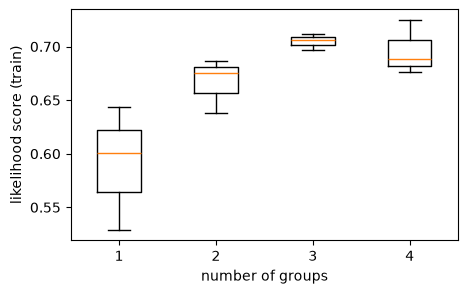

In [ ]:
NTYPES = [1, 2, 3, 4]
RUNS = 3

def train_or_load(ntypes: int, run: int) -> FlockeExperiment:
    exp = make_experiment(ntypes)
    model_path = ROOT / 'trained_models' / EMBEDDER / NAME / f'g{ntypes}_ep{MAX_EPOCHS}_run{run}.pth'
    seed_everything(run)
    if not exp.load_or_train_model(filepath=str(model_path)):
        exp.save_model(str(model_path))
    return exp

scores = pd.DataFrame([{'ntypes': ntypes, 'run_id': run, 'exp_score_train': likelihood_score(train_or_load(ntypes, run), 'train')}
                       for ntypes in NTYPES for run in range(RUNS)])

fig, ax = plt.subplots(figsize=(5, 3))
ax.boxplot([scores.loc[scores['ntypes'] == n, 'exp_score_train'] for n in NTYPES], tick_labels=NTYPES)
ax.set(xlabel='number of groups', ylabel='likelihood score')
plt.show()

In [ ]:
N_GROUPS = 3
print_calibration(scores, N_GROUPS)


Likelihood score (train) by number of groups:
         mean  median    std
ntypes                      
1      0.5909  0.6006 0.0579
2      0.6665  0.6757 0.0257
3      0.7049  0.7057 0.0075
4      0.6964  0.6880 0.0252
Calibration gain ΔL-2 (n=3 vs n=1): 0.1140 (mean), 0.1051 (median)
Calibration gain ΔL-1 (n=3 vs n=2): 0.0384 (mean), 0.0300 (median)
Calibration gain ΔL+1 (n=4 vs n=3): -0.0085 (mean), -0.0177 (median)


## 4. Inspecting the model

We keep the run with the highest score among those with `N_GROUPS` groups. `print_trained_Flocke()` plots the size of each group (sum of the annotator memberships) and the training loss, and prints the group prior.

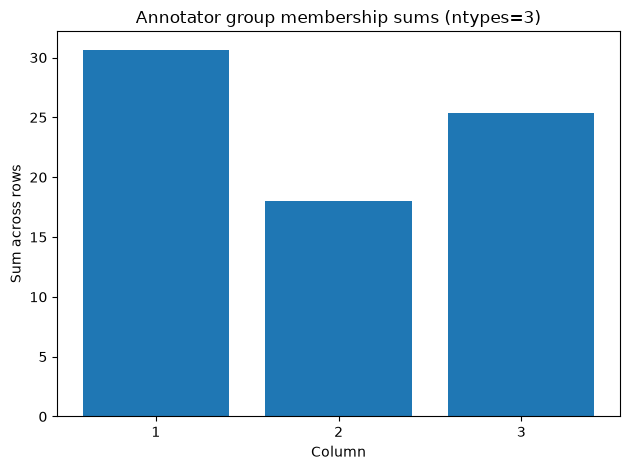

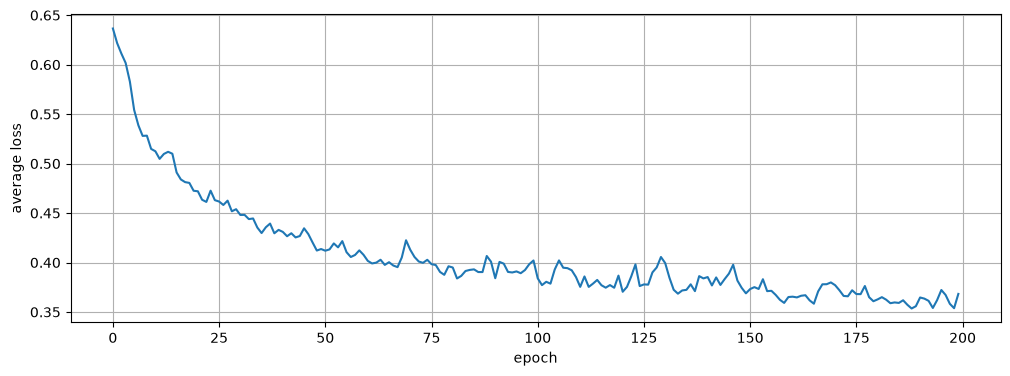

Z priors: [0.40621513 0.2520119  0.34177294]
Final loss value: 0.3683
Avg. loss in the last 50 epochs: 0.3661


In [ ]:
exp = train_or_load(N_GROUPS, best_run(scores, N_GROUPS))
exp.print_trained_Flocke()

**Annotator groups.** `train_pug` holds each training annotator's soft membership over the groups; `predicted_groups` assigns each annotator to their most likely group.

In [ ]:
groups = predicted_groups(exp)
print({g: len(annotators) for g, annotators in groups.items()})

id_to_annotator = exp.metadata['train']['id_to_annotator']
membership = pd.DataFrame(exp.train_pug, columns=[f'group {g}' for g in range(N_GROUPS)])
membership.index = [id_to_annotator.get(i) for i in range(len(membership))]
membership.round(3).head()

{0: 30, 1: 17, 2: 27}


,group 0,group 1,group 2
Ann0,0.891,0.0,0.109
Ann1,0.912,0.0,0.088
Ann10,0.000,0.0,1.000
Ann11,1.000,0.0,0.000
Ann12,0.010,0.0,0.990


**Group predictions.** Every group can label any item, including unseen ones. `group_predictions(split)` returns, for each item, the label distribution predicted by each group (`predictions`, shape groups × classes), the most likely label of each group (`predicted_labels`), and the observed `soft_label`.

In [ ]:
group_preds = exp.group_predictions('test')
group_preds.head()

,example_id,text,predictions,predicted_labels,soft_label
0,0,{'post': 'Red rooster is the fucking worst fas...,"[[0.9697765707969666, 0.0302234198898077], [0....","[0, 1, 0]","[0.2, 0.8]"
1,19,"{'post': 'You can smell the desperation', 'rep...","[[0.5437985062599182, 0.4562014937400818], [0....","[0, 1, 0]","[0.2, 0.8]"
2,30,{'post': 'What does this mean? Can somebody EL...,"[[0.9951733946800232, 0.004826616961508989], [...","[0, 1, 0]","[0.8, 0.2]"
3,31,{'post': 'I want to post a cute thirst trap bu...,"[[0.9965121150016785, 0.003487849608063698], [...","[0, 0, 0]","[0.6, 0.4]"
4,34,"{'post': 'But it IS the slab's fault, little f...","[[0.6779869794845581, 0.3220130503177643], [0....","[0, 1, 1]","[0.8333333333333334, 0.16666666666666666]"


**Most relevant items.** The items on which groups disagree most are those where their predicted distributions are furthest apart (Jensen-Shannon divergence, per pair of groups and on average).

In [ ]:
js = pairwise_js_divergences(group_preds, N_GROUPS)
pd.set_option('display.max_colwidth', 120)
js.sort_values('avg_js_div', ascending=False).head(5)

,example_id,text,js_div_g0_g1,js_div_g0_g2,js_div_g1_g2,avg_js_div
8,50,"{'post': 'Not every murder becomes big news.', 'reply': 'When it's a man killing a woman it does..'}",0.696845,0.325118,0.423834,0.481932
266,2319,"{'post': 'Masturbated to catchphrase at Saturday dinner time.', 'reply': 'It’s good, but it’s not right'}",0.671987,0.260496,0.458331,0.463605
127,1090,"{'post': 'Today, I am seven years sober.', 'reply': '@USER Congratulations'}",0.674051,0.425369,0.291327,0.463582
88,751,{'post': 'I couldn't believe it when I watched him say this in question time. What an absolute numpty. Not only wha...,0.669788,0.272578,0.443093,0.461820
20,150,"{'post': 'I think it's a serious threat to our society. But I've known quite a few still think it's just a flu.', 'r...",0.648945,0.234610,0.463642,0.449066


## 5. Evaluating with your own metrics

To predict how a given annotator labels an item, mix the group predictions with the annotator's membership. Annotators not seen in training fall back to the group prior. The function below returns one row per annotation of a split, so any metric can be computed from it, either per annotation or aggregated per item (as in `soft_label_prediction` in `experiments.py`).

> `exp.perspectivist_predictions(split)` does something similar, but it estimates the memberships from the labels of `split` itself: use it to analyze the training data, not to evaluate on held-out items.

In [ ]:
def annotation_predictions(exp: FlockeExperiment, split: str) -> pd.DataFrame:
    seen = set(int(a) for a in np.unique(exp.flocke_data['train']._u))
    prior = np.asarray(exp.dr._z_priors, dtype=float)

    def membership(annotator):
        a = exp.annotator_mapping[annotator]
        return np.asarray(exp.train_pug[a], dtype=float) if a in seen and a < len(exp.train_pug) else prior

    group_preds = exp.group_predictions(split)
    rows = []
    for example_id, preds in zip(group_preds['example_id'], group_preds['predictions']):
        for annotator, label in exp.data_files[split][example_id]['annotations'].items():
            rows.append({
                'example_id': example_id,
                'annotator': annotator,
                'seen_in_train': exp.annotator_mapping[annotator] in seen,
                'label': exp.label_mapping[label],
                'prediction': membership(annotator) @ np.asarray(preds),  # distribution over classes
            })
    return pd.DataFrame(rows)

annotations = annotation_predictions(exp, 'test')
annotations.head()

,example_id,annotator,seen_in_train,label,prediction
0,0,Ann0,True,1,"[0.9557820688207793, 0.044217979246990904]"
1,0,Ann17,True,1,"[0.8408532922866291, 0.15914671220041557]"
2,0,Ann61,True,1,"[0.8408354285817022, 0.1591645677375861]"
3,0,Ann63,True,1,"[0.840821051068016, 0.15917887660409483]"
4,0,Ann65,True,0,"[0.840836109171386, 0.1591638643824142]"


In [ ]:
# Per annotation: macro-F1 of the predicted labels, for annotators seen / unseen in training
annotations['predicted_label'] = annotations['prediction'].apply(np.argmax)
for seen, sub in annotations.groupby('seen_in_train'):
    print(f"Annotation macro-F1 (seen in train = {seen}, n = {len(sub)}): {f1_score(sub['label'], sub['predicted_label'], average='macro'):.3f}")

# Per item: the predicted soft label is the average over the item's annotators
item_preds = annotations.groupby('example_id', sort=False)['prediction'].apply(lambda p: np.mean(np.stack(p), axis=0))
targets = np.array([[exp.data_files['test'][i]['soft_label'][label] for label in LABELS] for i in item_preds.index])
predictions = np.stack(item_preds.to_numpy())
print(f'Soft-label cross-entropy: {cross_entropy(targets, predictions):.3f}')
print(f'Soft-label Wasserstein distance: {average_WS(targets, predictions):.3f}')

Annotation macro-F1 (seen in train = True, n = 1583): 0.585
Soft-label cross-entropy: 0.791
Soft-label Wasserstein distance: 0.263
